# EDA del set de práctica

Qué hay en los datos, antes de cualquier modelo. Cada sección responde una pregunta y cierra
con una conclusión de una línea y **qué decisión del pipeline sale de ahí**.

Lee las capas del lago (`lake/practica`, generadas con `make practica`) y, solo donde se
indica, la verdad de `datos/practica/verdad`. Lo que usa la verdad **no está disponible en el
set final**: sirve para entender, no para el pipeline.

In [1]:
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LAGO, VERDAD = RAIZ / "lake" / "practica", RAIZ / "datos" / "practica" / "verdad"
con = duckdb.connect()
con.execute("SET TimeZone='America/Argentina/Buenos_Aires'")
for capa in ("silver", "gold"):
    for f in sorted((LAGO / capa).glob("*.parquet")):
        con.execute(f"CREATE VIEW {capa}_{f.stem} AS SELECT * FROM read_parquet('{f}')")
con.execute(f"CREATE VIEW v_com AS SELECT * FROM read_csv('{VERDAD}/comentarios.csv.gz', all_varchar=true)")
con.execute(f"CREATE VIEW v_cue AS SELECT cuenta_id, coalesce(campana_id, 'genuina') AS campana FROM read_csv('{VERDAD}/cuentas.csv.gz', all_varchar=true)")
con.execute(f"CREATE VIEW v_nar AS SELECT * FROM read_csv('{VERDAD}/narrativas.csv', all_varchar=true)")
# Tema de cada publicación (por mayoría de sus comentarios con narrativa; usa la verdad)
con.execute('''CREATE TABLE tema_pub AS
    SELECT publicacion_id, mode(n.tema) AS tema FROM silver_comentarios c JOIN v_com USING (comentario_id)
    JOIN v_nar n ON n.narrativa_id = v_com.narrativa_id GROUP BY 1''')
q = lambda sql: con.execute(sql).df()

# Paleta (categórica validada) y estilo: marcas finas, grilla discreta
TEMA = {"litio": "#2a78d6", "colectivo": "#eb6834", "hospital": "#1baf7a"}
CAMP = {"genuina": "#a3a29c", "C1": "#6250d6", "C2": "#e87ba4", "C3": "#eda100"}
POST = {"apoya": "#2a78d6", "rechaza": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 3.4), "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b9b8b2",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
miles = mt.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

## 1. Forma y calidad
¿Cuánto hay y qué tan sucio está?

In [2]:
q('''SELECT 'comentarios' tabla, count(*) filas FROM silver_comentarios UNION ALL
     SELECT 'textos únicos', count(*) FROM silver_textos UNION ALL
     SELECT 'cuentas', count(*) FROM silver_cuentas UNION ALL
     SELECT 'publicaciones', count(*) FROM silver_publicaciones UNION ALL
     SELECT 'días', count(DISTINCT dia_local) FROM silver_comentarios''')

,tabla,filas
0,comentarios,200000
1,textos únicos,58344
2,cuentas,15991
3,publicaciones,506
4,días,14


In [3]:
q('''SELECT flag, count(*) AS comentarios, round(100.0 * count(*) / (SELECT count(*) FROM silver_comentarios), 2) AS pct
     FROM (SELECT unnest(flags) AS flag FROM silver_comentarios) GROUP BY 1 ORDER BY 2 DESC''')

,flag,comentarios,pct
0,texto_vacio,2159,1.08


**Conclusión.** 200 mil comentarios, pero solo 58 mil textos distintos: cada texto aparece 3,4 veces en promedio. La práctica viene casi limpia (1% de textos vacíos); el final puede venir más sucio y silver ya lo resuelve (`tests/`).
**Decisión:** trabajar por texto único (`silver/textos`), no por comentario.

## 2. Tiempo
¿Cómo se reparte la conversación en los 14 días y en el día?

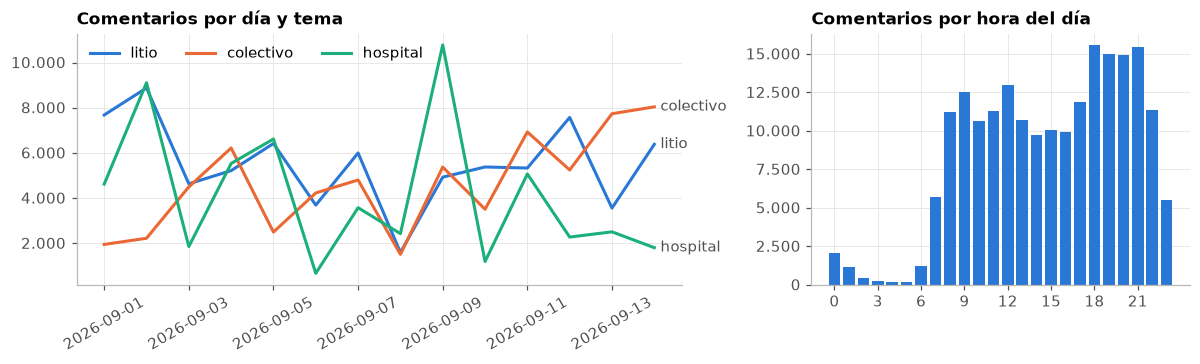

In [4]:
d = q('''SELECT dia_local AS dia, t.tema, count(*) n FROM silver_comentarios JOIN tema_pub t USING (publicacion_id)
         GROUP BY 1, 2 ORDER BY 1''').pivot(index="dia", columns="tema", values="n").fillna(0)
h = q('''SELECT hora_local AS hora, count(*) n FROM silver_comentarios GROUP BY 1 ORDER BY 1''')
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
for t, c in TEMA.items():
    a.plot(d.index, d[t], color=c, label=t)
    a.annotate(t, (d.index[-1], d[t].iloc[-1]), xytext=(4, 0), textcoords="offset points", color="#52514e", va="center")
a.set_title("Comentarios por día y tema"); a.yaxis.set_major_formatter(miles); a.legend(loc="upper left", ncols=3)
a.tick_params(axis="x", rotation=30)
b.bar(h.hora, h.n, color="#2a78d6", width=0.8); b.set_title("Comentarios por hora del día"); b.yaxis.set_major_formatter(miles)
b.set_xticks(range(0, 24, 3)); plt.tight_layout()

**Conclusión.** Ritmo diurno muy marcado (casi nada entre la 1 y las 6, pico de 18 a 22 h) y días virales distintos en cada tema (hospital salta a 11 mil el 9/9).
**Decisión:** la coordinación compara contra la densidad del momento y la publicación, nunca contra un umbral fijo: un pico viral es genuino.

## 3. Publicaciones y fuentes
¿Todas las publicaciones reciben lo mismo?

,count,mean,std,min,50%,90%,99%,max
comentarios por publicación,506.0,395.0,610.0,3.0,222.0,798.0,2574.0,6793.0


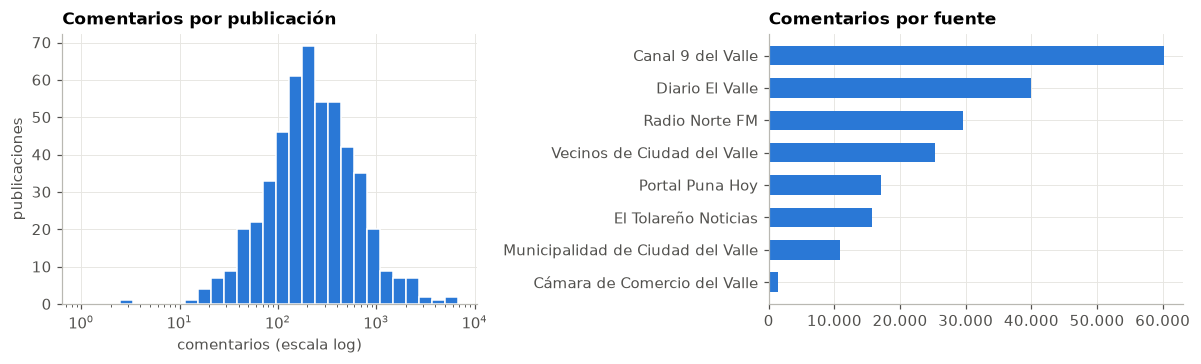

In [5]:
p = q('''SELECT p.publicacion_id, f.nombre fuente, f.tipo, count(c.comentario_id) n
         FROM silver_publicaciones p JOIN silver_fuentes f USING (fuente_id)
         LEFT JOIN silver_comentarios c USING (publicacion_id) GROUP BY ALL''')
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
a.hist(p.n, bins=np.logspace(0, np.log10(p.n.max() + 1), 30), color="#2a78d6", edgecolor="white", linewidth=1)
a.set_xscale("log"); a.set_title("Comentarios por publicación"); a.set_xlabel("comentarios (escala log)"); a.set_ylabel("publicaciones")
f = p.groupby("fuente").n.agg(["sum", "count"]).sort_values("sum")
b.barh(f.index, f["sum"], color="#2a78d6", height=0.6); b.set_title("Comentarios por fuente"); b.xaxis.set_major_formatter(miles)
plt.tight_layout()
p.n.describe(percentiles=[.5, .9, .99]).round(0).to_frame("comentarios por publicación").T

**Conclusión.** Muy desparejas: mediana de 222 comentarios por publicación, pero el 1% supera los 2.500 y la mayor tiene 6.793. Veinte comentarios en diez minutos es normal en unas y rarísimo en otras.
**Decisión:** la sorpresa de coincidir se calcula con la densidad local de cada publicación (ventana ±30 min).

## 4. Cuentas
¿Quién comenta? ¿Las cuentas de campaña se ven distintas? *(campaña: usa la verdad)*

,cuentas,comentarios_mediana,antiguedad_mediana,temas_promedio
campana,,,,
C1,60,6.0,4.0,1.5
C2,30,19.0,1248.5,3.0
C3,25,5.0,1.0,1.0
genuina,15876,6.0,3231.0,2.6


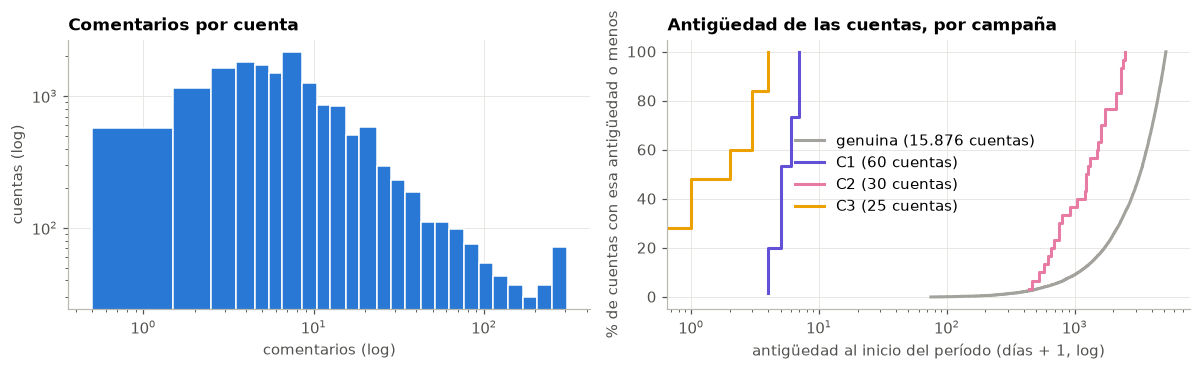

In [6]:
a_ = q('''SELECT c.cuenta_id, v.campana, count(*) n, count(DISTINCT t.tema) temas, any_value(s.antiguedad_dias) antiguedad
          FROM silver_comentarios c JOIN v_cue v USING (cuenta_id) JOIN tema_pub t USING (publicacion_id)
          LEFT JOIN silver_cuentas s USING (cuenta_id) GROUP BY 1, 2''')
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
a.hist(a_.n, bins=np.unique(np.round(np.logspace(0, np.log10(a_.n.max() + 1), 30))) - 0.5, color="#2a78d6", edgecolor="white", linewidth=1)
a.set_xscale("log"); a.set_yscale("log"); a.set_title("Comentarios por cuenta"); a.set_xlabel("comentarios (log)"); a.set_ylabel("cuentas (log)")
for k, c in CAMP.items():
    x = np.sort(a_[a_.campana == k].antiguedad.dropna().values) + 1
    b.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where="post", color=c, linewidth=2, label=f"{k} ({len(x):,} cuentas)".replace(",", "."))
b.set_xscale("log"); b.set_xlabel("antigüedad al inicio del período (días + 1, log)"); b.set_ylabel("% de cuentas con esa antigüedad o menos")
b.set_title("Antigüedad de las cuentas, por campaña"); b.legend(loc="center left", bbox_to_anchor=(0.22, 0.5))
plt.tight_layout()
a_.groupby("campana").agg(cuentas=("n", "size"), comentarios_mediana=("n", "median"),
                          antiguedad_mediana=("antiguedad", "median"), temas_promedio=("temas", "mean")).round(1)

**Conclusión.** La mayoría comenta poco (mediana 6) y los genuinos opinan en 2,6 temas en promedio. C1 y C3 son cuentas recién creadas (4 y 1 días), pero **C2 son cuentas viejas** (1.248 días) que comentan en los 3 temas como cobertura.
**Decisión:** la antigüedad sola no alcanza (C2 pasaría); lo que delata a las tres es coincidir una y otra vez, así que la coordinación se basa en co-ocurrencia y no en atributos de la cuenta.

## 5. Textos
¿Cuánto se repite la gente? ¿Cómo son los textos?

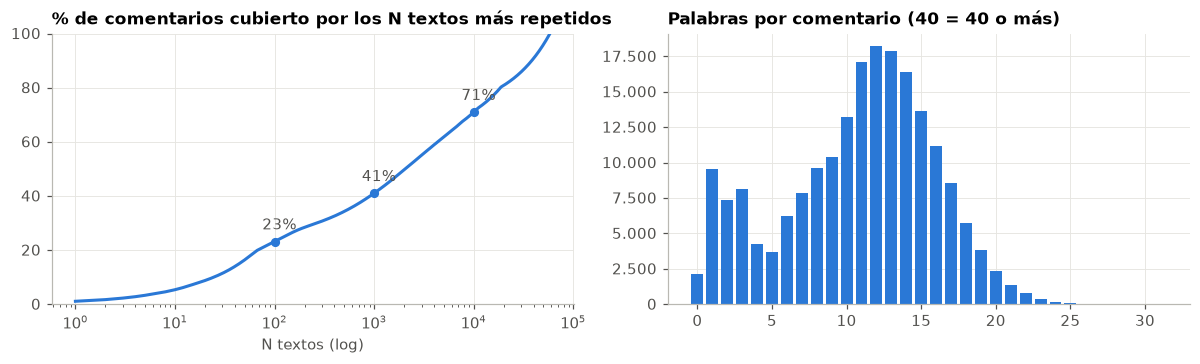

In [7]:
t = q('SELECT n_comentarios, n_tokens FROM silver_textos ORDER BY n_comentarios DESC')
cum = t.n_comentarios.cumsum() / t.n_comentarios.sum()
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
a.plot(np.arange(1, len(cum) + 1), cum * 100, color="#2a78d6"); a.set_xscale("log")
for k in (100, 1000, 10000):
    a.annotate(f"{cum.iloc[k-1]*100:.0f}%", (k, cum.iloc[k-1] * 100), xytext=(-8, 8), textcoords="offset points", color="#52514e")
    a.plot(k, cum.iloc[k-1] * 100, "o", color="#2a78d6", markersize=5)
a.set_title("% de comentarios cubierto por los N textos más repetidos"); a.set_xlabel("N textos (log)"); a.set_ylim(0, 100)
tok = q('SELECT least(n_tokens, 40) tok, count(*) n FROM silver_comentarios GROUP BY 1 ORDER BY 1')
b.bar(tok.tok, tok.n, color="#2a78d6", width=0.8); b.set_title("Palabras por comentario (40 = 40 o más)"); b.yaxis.set_major_formatter(miles)
plt.tight_layout()

In [8]:
# Los textos más repetidos y a qué narrativa pertenecen (verdad)
q('''SELECT any_value(c.texto_limpio) texto, count(*) comentarios, count(DISTINCT c.cuenta_id) cuentas,
            mode(v.narrativa_id) narrativa
     FROM silver_comentarios c JOIN v_com v USING (comentario_id) GROUP BY c.texto_id ORDER BY 2 DESC LIMIT 12''')

,texto,comentarios,cuentas,narrativa
0,,2159,1700,ninguna
1,Gracias por la info,1222,1020,ninguna
2,En que calle queda la obra?,1131,971,ninguna
3,Hay que pedir turno por teléfono o presencial?,1042,916,ninguna
4,Gracias por informar,1014,871,ninguna
5,Alguien sabe si atienden pediatria el sabado?,985,843,ninguna
6,a qué hora pasa la última?,796,700,ninguna
7,Alguien sabe a qué hora es la asamblea?,789,703,ninguna
8,Comparto,786,702,ninguna
9,Hay video de la audiencia?,781,697,ninguna


**Conclusión.** Hay plantillas: 100 textos cubren el 23% de los comentarios y 10 mil textos, el 71%. Los textos más repetidos son **todos ruido** (vacíos, "Gracias por la info", preguntas prácticas). La distribución de palabras tiene dos jorobas: textos de 1 a 4 palabras y opiniones de 8 a 18.
**Decisión:** clusters de textos casi iguales (micro-clusters) y un tipo *genérico* para los textos muy cortos, que no deciden narrativa.

## 6. Conversación
¿Quién responde a quién? *(narrativa y postura: usa la verdad)*

In [9]:
q('''SELECT count(*) comentarios, count(*) FILTER (WHERE es_respuesta) respuestas,
            round(100.0 * count(*) FILTER (WHERE es_respuesta) / count(*), 1) pct_respuestas,
            (SELECT count(*) FROM silver_comentarios h JOIN silver_comentarios p ON p.comentario_id = h.respuesta_a
             WHERE p.es_respuesta) respuestas_a_respuestas,
            (SELECT count(*) FROM silver_comentarios h JOIN silver_comentarios p ON p.comentario_id = h.respuesta_a
             WHERE p.publicacion_id <> h.publicacion_id) respuestas_a_otra_publicacion
     FROM silver_comentarios''')

,comentarios,respuestas,pct_respuestas,respuestas_a_respuestas,respuestas_a_otra_publicacion
0,200000,28054,14.0,4753,0


In [10]:
r = q('''SELECT CASE WHEN vh.narrativa_id = 'ninguna' OR vp.narrativa_id = 'ninguna' THEN 'involucra ruido'
                     WHEN vh.narrativa_id <> vp.narrativa_id THEN 'otra narrativa'
                     WHEN vh.postura = vp.postura THEN 'misma narrativa, misma postura'
                     ELSE 'misma narrativa, postura opuesta' END AS relacion, count(*) respuestas
         FROM silver_comentarios h JOIN silver_comentarios p ON p.comentario_id = h.respuesta_a
         JOIN v_com vh ON vh.comentario_id = h.comentario_id JOIN v_com vp ON vp.comentario_id = p.comentario_id
         GROUP BY 1 ORDER BY 2 DESC''')
r["pct"] = (100 * r.respuestas / r.respuestas.sum()).round(1); r

,relacion,respuestas,pct
0,"misma narrativa, postura opuesta",22477,80.1
1,"misma narrativa, misma postura",5577,19.9


In [11]:
q('''SELECT v.narrativa_id = 'ninguna' AS es_ruido, count(*) comentarios,
            round(100.0 * avg(c.es_respuesta::int), 1) pct_que_responde,
            round(100.0 * avg((EXISTS (SELECT 1 FROM silver_comentarios h WHERE h.respuesta_a = c.comentario_id))::int), 1) pct_que_recibe,
            round(avg(c.n_tokens), 1) palabras
     FROM silver_comentarios c JOIN v_com v USING (comentario_id) GROUP BY 1''')

,es_ruido,comentarios,pct_que_responde,pct_que_recibe,palabras
0,True,37710,0.0,0.0,3.5
1,False,162290,17.3,15.7,12.5


**Conclusión.** Es la señal más fuerte del set. El 14% son respuestas y **ninguna** cruza de publicación ni de narrativa: el 80% responde desde la postura opuesta y el 20% desde la misma. El ruido nunca responde ni recibe respuestas, y es corto (3,5 palabras contra 12,5).
**Decisión:** las narrativas se arman uniendo micro-clusters por el grafo de respuestas, los lados se separan con un corte máximo y un cluster que no participa de conversaciones es ruido.

## 7. Narrativas *(todo con la verdad)*
¿Cuántas hay, de qué tamaño, cuándo nacen y se separan en el espacio de embeddings?

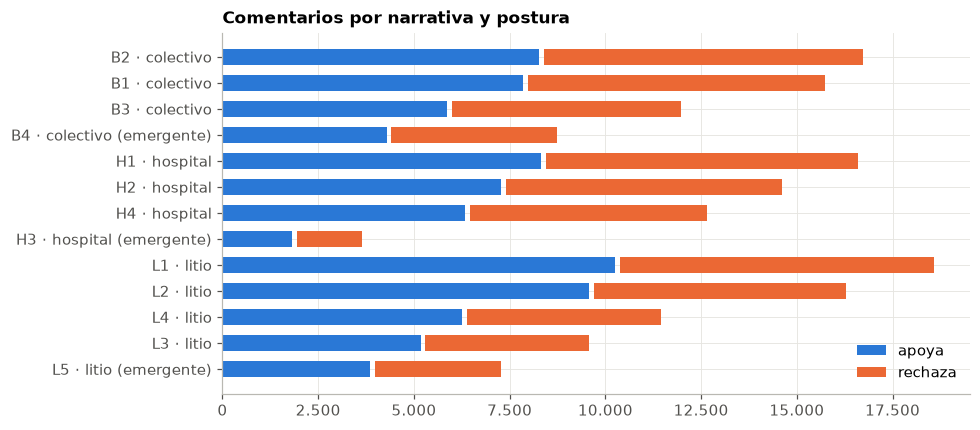

In [12]:
n = q('''SELECT v.narrativa_id nar, n.tema, n.emergente, v.postura, count(*) k
         FROM v_com v JOIN v_nar n USING (narrativa_id) GROUP BY ALL''')
w = n.pivot_table(index=["nar", "tema", "emergente"], columns="postura", values="k", fill_value=0).reset_index()
w["total"] = w.apoya + w.rechaza; w = w.sort_values(["tema", "total"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(w))
ax.barh(y, w.apoya, color=POST["apoya"], height=0.62, label="apoya")
ax.barh(y, w.rechaza, left=w.apoya + 120, color=POST["rechaza"], height=0.62, label="rechaza")
ax.set_yticks(y, [f"{r.nar} · {r.tema}{' (emergente)' if r.emergente == 'si' else ''}" for r in w.itertuples()])
ax.xaxis.set_major_formatter(miles); ax.set_title("Comentarios por narrativa y postura"); ax.legend(loc="lower right")
plt.tight_layout()

/var/folders/q2/zyvpwp796nsgch304b1xpm7m0000gn/T/ipykernel_98255/2823959683.py:20: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  q = lambda sql: con.execute(sql).df()


,narrativa_id,tema,fecha_origen,publicacion_origen
0,L5,litio,2026-09-07T08:17:26-03:00,p00212
1,B4,colectivo,2026-09-10T21:32:05-03:00,p00318
2,H3,hospital,2026-09-06T01:12:04-03:00,p00177


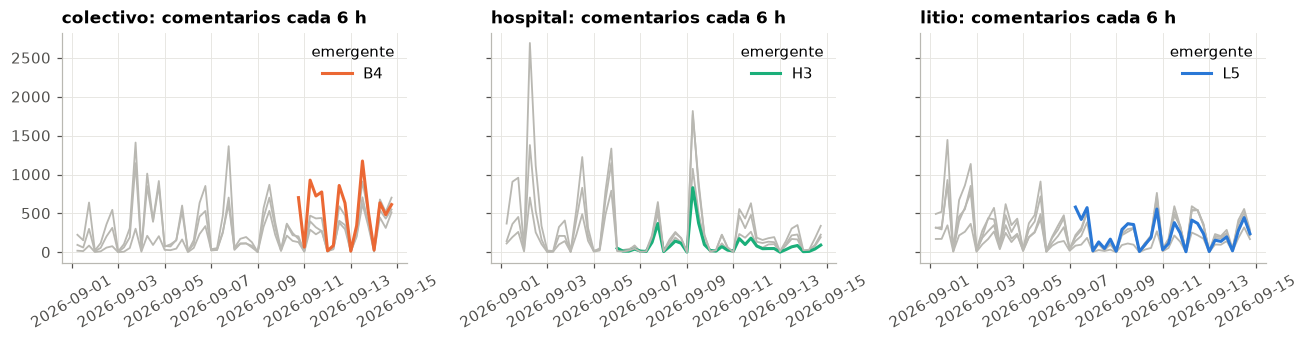

In [13]:
dd = q('''SELECT v.narrativa_id nar, n.tema, n.emergente, date_trunc('hour', c.ts) - INTERVAL (hour(c.ts) % 6) HOUR AS t, count(*) k
          FROM silver_comentarios c JOIN v_com v USING (comentario_id) JOIN v_nar n USING (narrativa_id) GROUP BY ALL''')
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (tema, g) in zip(axs, dd.groupby("tema")):
    for i, (nar, x) in enumerate(g.groupby("nar")):
        x = x.sort_values("t"); em = x.emergente.iloc[0] == "si"
        ax.plot(x.t, x.k, color=TEMA[tema] if em else "#b9b8b2", linewidth=2 if em else 1.2, label=nar if em else None)
    ax.set_title(f"{tema}: comentarios cada 6 h"); ax.tick_params(axis="x", rotation=30); ax.legend(title="emergente")
plt.tight_layout()
q("SELECT narrativa_id, tema, fecha_origen, publicacion_origen FROM v_nar WHERE emergente = 'si'")

Text(0.0, 1.0, 'Mapa de los 6.000 textos más frecuentes (t-SNE de los embeddings)')

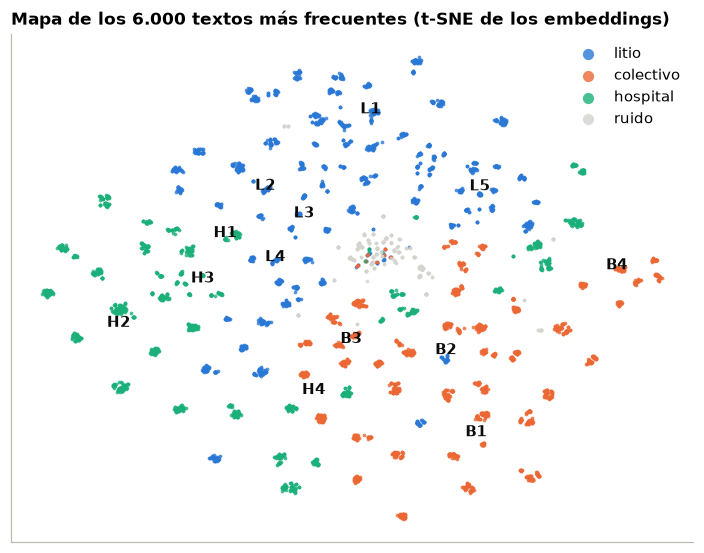

In [14]:
from sklearn.manifold import TSNE
e = con.execute(f"SELECT texto_id, vector FROM read_parquet('{LAGO}/gold/embeddings.parquet')").df()
lab = q('''SELECT c.texto_id, mode(v.narrativa_id) nar, count(*) k FROM silver_comentarios c JOIN v_com v USING (comentario_id)
           GROUP BY 1''').merge(q("SELECT narrativa_id nar, tema FROM v_nar"), how="left").fillna({"tema": "ruido"})
m = e.merge(lab, on="texto_id").sort_values("k", ascending=False).head(6000)
xy = TSNE(n_components=2, init="pca", random_state=0, perplexity=40).fit_transform(np.stack(m.vector.values))
fig, ax = plt.subplots(figsize=(8, 6))
for tema, c in {**TEMA, "ruido": "#d4d3cd"}.items():
    s = (m.tema == tema).values
    ax.scatter(xy[s, 0], xy[s, 1], s=6, color=c, label=tema, alpha=0.8, linewidths=0)
for nar, g in m.assign(x=xy[:, 0], y=xy[:, 1])[m.nar != "ninguna"].groupby("nar"):
    ax.annotate(nar, (g.x.median(), g.y.median()), ha="center", fontweight="bold", color="#0b0b0b")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.legend(markerscale=3, loc="best")
ax.set_title("Mapa de los 6.000 textos más frecuentes (t-SNE de los embeddings)")

**Conclusión.** 13 narrativas (4 o 5 por tema) de 3.500 a 18.500 comentarios, con los dos lados bastante parejos. Las tres emergentes nacen a mitad del período (días 6, 7 y 10). En el mapa de embeddings cada narrativa es un archipiélago de islas chicas (sus plantillas), los temas ocupan zonas distintas y el ruido queda en el centro.
**Decisión:** primero micro-clusters y después unirlos por respuestas (los embeddings solos no juntan las islas de una narrativa). El origen se busca dentro de cada narrativa, no en el set.

## 8. Coordinación *(campañas: usa la verdad)*
¿Qué delata a una operación? Coincidencias observadas frente a las esperables por azar.

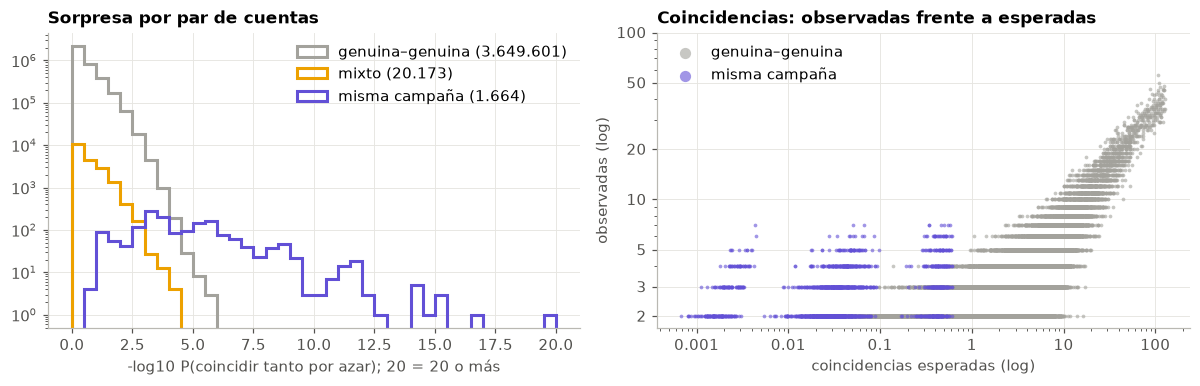

In [15]:
import sys; sys.path.insert(0, str(RAIZ))
from qd import coordinacion
from qd.lago import Lago
cl = Lago(LAGO).conectar()
pares, _ = coordinacion.pares(cl, Lago(LAGO), coordinacion.PARAMS)
camp = dict(q("SELECT cuenta_id, campana FROM v_cue").values)
ca, cb = pares.a.map(camp), pares.b.map(camp)
pares["tipo"] = np.where((ca == cb) & (ca != "genuina"), "misma campaña",
                 np.where((ca == "genuina") & (cb == "genuina"), "genuina–genuina", "mixto"))
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(0, 20, 41)
for tipo, c in {"genuina–genuina": "#a3a29c", "mixto": "#eda100", "misma campaña": "#6250d6"}.items():
    a.hist(pares[pares.tipo == tipo].sorpresa.clip(upper=19.99), bins=bins, histtype="step", color=c, linewidth=2, label=f"{tipo} ({(pares.tipo == tipo).sum():,})".replace(",", "."))
a.set_yscale("log"); a.set_title("Sorpresa por par de cuentas"); a.set_xlabel("-log10 P(coincidir tanto por azar); 20 = 20 o más"); a.legend()
s = pares.sample(min(len(pares), 60000), random_state=0)
for tipo, c in {"genuina–genuina": "#a3a29c", "misma campaña": "#6250d6"}.items():
    x = s[s.tipo == tipo] if tipo != "misma campaña" else pares[pares.tipo == tipo]
    b.scatter(x.esperado, x.k, s=6, color=c, alpha=0.6, linewidths=0, label=tipo)
b.set_xscale("log"); b.set_yscale("log"); b.set_xlabel("coincidencias esperadas (log)"); b.set_ylabel("observadas (log)")
b.set_title("Coincidencias: observadas frente a esperadas"); b.legend(markerscale=3)
for eje in (b.xaxis, b.yaxis):
    eje.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}")); eje.set_minor_formatter(mt.NullFormatter())
b.set_yticks([2, 3, 5, 10, 20, 50, 100])
plt.tight_layout()

In [16]:
# Firma de cada campaña
q('''WITH c AS (SELECT c.*, v.campana FROM silver_comentarios c JOIN v_cue v USING (cuenta_id))
     SELECT campana, count(DISTINCT cuenta_id) cuentas, count(*) comentarios, count(DISTINCT publicacion_id) publicaciones,
            round(count(DISTINCT texto_id) * 1.0 / count(*), 2) textos_distintos_por_comentario,
            round(100.0 * avg(es_respuesta::int), 1) pct_respuestas,
            round(100.0 * avg((len(hashtags) > 0)::int), 1) pct_con_hashtag,
            round(100.0 * avg((hora_local BETWEEN 8 AND 20)::int), 1) pct_diurno
     FROM c GROUP BY 1 ORDER BY 1''')

,campana,cuentas,comentarios,publicaciones,textos_distintos_por_comentario,pct_respuestas,pct_con_hashtag,pct_diurno
0,C1,60,376,63,0.23,18.4,45.7,86.4
1,C2,30,564,206,0.76,22.3,0.0,73.8
2,C3,25,125,9,0.13,16.8,27.2,0.0
3,genuina,15876,198935,506,0.29,14.0,0.0,78.3


**Conclusión.** Lo que delata a una operación no es la cantidad de coincidencias sino que sean **improbables**. Pares genuinos muy activos coinciden 40 o más veces, pero se esperaban unas 100. Los pares de una campaña coinciden de 2 a 7 veces cuando se esperaba 0,001–0,5, y su sorpresa supera la de casi todos los 3,6 millones de pares genuinos. Cada campaña tiene otra firma: C1 usa hashtag propio y textos repetidos, C2 textos variados en 206 publicaciones, y C3 publica de madrugada (0% diurno) en solo 9 publicaciones.
**Decisión:** sorpresa Poisson por par de cuentas, con umbrales que dependen de cuántos pares se prueban y no de la firma de una campaña en particular, porque el final trae campañas nuevas.

## 9. Supuestos que usa el pipeline
Lo que el pipeline da por cierto. Los que no necesitan verdad se verifican en cada corrida (`gold/supuestos`), así que el viernes vamos a saber si el set final los cumple.

In [17]:
pd.read_parquet(LAGO / "gold" / "supuestos.parquet")

,chequeo,valor,esperado,ok,depende
0,respuestas que cruzan de publicación,0.00,0,True,las respuestas heredan la narrativa del padre;...
1,respuestas anteriores a su padre,0.00,0,True,el orden temporal de la asignación y del origen
2,% respuestas,14.00,>= 5,True,las narrativas se arman con el grafo de respue...
3,% respuestas con padre desconocido,0.00,< 5,True,grafo de respuestas incompleto
4,textos únicos / comentarios,0.29,< 0.6,True,micro-clusters de plantillas; caché de embeddings
5,% sin fecha,0.00,< 1,True,coordinación por ventanas de tiempo y origen
6,% sin cuenta,0.00,< 1,True,coordinación por pares de cuentas
7,narrativas encontradas,13.00,3 a 40,True,resolución de Leiden
8,% comentarios como ruido,17.90,5 a 40,True,umbral de participación de los micro-clusters
9,% cuentas marcadas como coordinadas,0.68,< 3,True,precisión de coordinación: las campañas son po...
